# 08. Динамика рынка 2024–2026

Данные: мастер-датасет `vacancies_2024_2026_master.csv.gz` (ноутбук 09): 53 916 вакансий hh, lalafo и Telegram,
январь 2024 – октябрь 2026, единые правила, даты во времени Бишкека.

**Вопросы:**
1. Можно ли сравнивать источники между собой?
2. Как менялись предлагаемые зарплаты с 2024 по 2026 год, если убрать влияние состава вакансий?
3. Как это соотносится с официальной средней зарплатой?
4. Какие профессии подорожали сильнее всего?
5. Что изменилось в сфере услуг?
6. Меняется ли доля скрытых зарплат и спрос по сферам?

Как и раньше: медианы вместо средних, группы меньше 30 зарплат не показываются.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")
rng = np.random.default_rng(42)

m = pd.read_csv("../data/processed/vacancies_2024_2026_master.csv.gz", low_memory=False, parse_dates=["reference_date"])
SOURCE = {"hh.kg": "headhunter", "lalafo.kg": "lalafo", "Telegram @codifynews": "telegram_codifynews",
          "Telegram @kgworkzone": "telegram_kgworkzone"}
df = pd.DataFrame({
    "published": m["reference_date"], "source": m["source"].map(SOURCE),
    "category": m["sector"], "sub_category": m["profession"],
    "experience": m["experience_required"].fillna("не указан"),    # неуказанный опыт: отдельная группа
    "experience_start": m["experience_min_years"],                  # пусто, если не указан
    "city": m["city_group"].fillna("не указан"),
    "compensation_currency": m["currency"],
    "salary_hidden": m["salary_status"] == "скрыта",
    "salary_kgs": m["salary_month_kgs"],
})
df["has_salary"] = df["salary_kgs"].notna()
df["q"] = df["published"].dt.to_period("Q").astype(str)
sal = df[df["has_salary"]].copy()
sal["ls"] = np.log(sal["salary_kgs"])
SRC = {"headhunter": "hh", "lalafo": "lalafo", "telegram_codifynews": "codifynews", "telegram_kgworkzone": "kgworkzone"}
df["src"] = df["source"].map(SRC); sal["src"] = sal["source"].map(SRC)
print(f"Вакансий с 2024 года: {len(df)} | с зарплатой: {len(sal)}")
pd.crosstab(sal["src"], sal["published"].dt.year, margins=True, margins_name="всего")

Вакансий с 2024 года: 53916 | с зарплатой: 26940


published,2024,2025,2026,всего
src,,,,
codifynews,6082,7572,5999,19653
hh,1875,0,0,1875
kgworkzone,0,284,1603,1887
lalafo,3525,0,0,3525
всего,11482,7856,7602,26940


## 1. Можно ли сравнивать источники?

В феврале–марте 2024 вакансии публиковались и на hh, и в канале codifynews. Если для **одних и тех же
профессий** в **одни и те же месяцы** зарплаты совпадают, то codifynews можно считать продолжением
рынка hh, а изменения во времени не объясняются сменой источника.

In [2]:
fm = sal[(sal["published"] >= "2024-02-01") & (sal["published"] < "2024-04-01")]
g = fm.groupby(["sub_category", "src"])["salary_kgs"].agg(["median", "size"]).unstack()
ok = (g["size"]["hh"] >= 10) & (g["size"]["codifynews"] >= 10)
same = pd.DataFrame({"hh": g["median"]["hh"][ok], "codifynews": g["median"]["codifynews"][ok],
                     "n_hh": g["size"]["hh"][ok], "n_codify": g["size"]["codifynews"][ok]})
same["codify / hh"] = (same["codifynews"] / same["hh"]).round(2)
print(f"Профессий с 10+ зарплатами в обоих источниках: {ok.sum()}")
print(f"Медиана отношения codifynews / hh: {same['codify / hh'].median():.2f}")
same.sort_values("codify / hh")

Профессий с 10+ зарплатами в обоих источниках: 9
Медиана отношения codifynews / hh: 1.00


,hh,codifynews,n_hh,n_codify,codify / hh
sub_category,,,,,
"Учитель, преподаватель, педагог",38000.0,30000.0,44.0,20.0,0.79
Специалист по подбору персонала,50000.0,45000.0,18.0,11.0,0.90
Специалист технической поддержки,32750.0,30000.0,10.0,17.0,0.92
"SMM-менеджер, контент-менеджер",35000.0,32500.0,49.0,48.0,0.93
"Менеджер по продажам, менеджер по работе с клиентами",50000.0,50000.0,255.0,270.0,1.00
"Менеджер по маркетингу, интернет-маркетолог",50000.0,50000.0,25.0,32.0,1.00
"Дизайнер, художник",44870.0,50000.0,26.0,36.0,1.11
"Программист, разработчик",101455.0,122805.0,34.0,266.0,1.21
Другое,40000.0,58170.0,146.0,75.0,1.45


In [3]:
# Тот же вопрос для всего набора совпадающих вакансий: перестановочный тест на разницу медиан
# внутри профессии (метка источника перемешивается внутри каждой профессии)
both = fm[fm["src"].isin(["hh", "codifynews"]) & fm["sub_category"].isin(same.index)]
groups = [(x["ls"].to_numpy(), (x["src"] == "codifynews").to_numpy()) for _, x in both.groupby("sub_category")]
def stat(gs):
    num = den = 0.0
    for y, f in gs:
        w = min(f.sum(), (~f).sum()); num += w * (np.median(y[f]) - np.median(y[~f])); den += w
    return num / den
obs = stat(groups)
perm = np.array([stat([(y, rng.permutation(f)) for y, f in groups]) for _ in range(3000)])
p = (np.abs(perm) >= abs(obs)).mean()
print(f"Разница codifynews против hh внутри профессии: {np.expm1(obs):+.1%}, p = {p:.2f}")

Разница codifynews против hh внутри профессии: +5.5%, p = 0.05


**Вывод простыми словами:**
- Для массовых профессий источники совпадают: менеджер по продажам (255 и 270 вакансий) и маркетолог
  получают одинаковые 50 000 сом и на hh, и в codifynews. Медиана отношения по 9 профессиям ровно **1,00**.
- Разница есть в IT: программисты в codifynews примерно на 20% дороже (123 тыс. против 101 тыс.),
  потому что в канале больше удалённых вакансий в долларах. В целом внутри профессии codifynews дороже
  примерно на **5,5%** (p = 0,05, на границе значимости).
- Поэтому динамика во времени считается **внутри одного источника** (codifynews), а сравнение «hh 2024 против
  codifynews 2026» без поправки могло бы завысить рост примерно на 5%.

## 2. Как менялись зарплаты: сырая медиана против индекса с поправкой на состав

Простая медиана по кварталам смешивает два эффекта: рост зарплат и изменение **состава** вакансий
(например, доли удалённых IT-вакансий в долларах). Поэтому строится **индекс с поправкой на состав**:
регрессия

```
log(зарплата) = квартал + профессия + опыт + город + валюта
```

Коэффициент квартала показывает, насколько дороже стала *та же самая* вакансия (та же профессия, опыт,
город, валюта) по сравнению с I кварталом 2024. Используется канал codifynews: это единственный источник,
который покрывает все кварталы.

In [4]:
cod = sal[sal["src"] == "codifynews"].copy()
by_q = cod.groupby("q").agg(вакансий=("ls", "size"), медиана=("salary_kgs", "median"),
                            доля_USD_EUR=("compensation_currency", lambda x: (x != "KGS").mean()))

def quarter_index(d):
    X = pd.get_dummies(d[["q", "sub_category", "experience", "city", "compensation_currency"]], drop_first=True, dtype=float)
    X.insert(0, "const", 1.0)
    b = np.linalg.lstsq(X.values, d["ls"].values, rcond=None)[0]
    c = pd.Series(b, index=X.columns)
    idx = c[c.index.str.startswith("q_")]
    idx.index = idx.index.str.replace("q_", "", regex=False)
    return pd.concat([pd.Series({"2024Q1": 0.0}), idx]).pipe(np.exp) * 100

idx = quarter_index(cod)
# 95% интервалы бутстрэпом по вакансиям (200 перевыборок)
boots = pd.DataFrame([quarter_index(cod.sample(len(cod), replace=True, random_state=i)) for i in range(200)])
by_q["индекс (I кв. 2024 = 100)"] = idx
by_q["95% ДИ"] = [f"{lo:.0f}–{hi:.0f}" for lo, hi in zip(boots.quantile(.025), boots.quantile(.975))]
by_q["медиана, индекс"] = by_q["медиана"] / by_q["медиана"].iloc[0] * 100
by_q.style.format({"медиана": "{:,.0f}", "доля_USD_EUR": "{:.0%}", "индекс (I кв. 2024 = 100)": "{:.1f}",
                   "медиана, индекс": "{:.1f}"})

,вакансий,медиана,доля_USD_EUR,индекс (I кв. 2024 = 100),95% ДИ,"медиана, индекс"
q,,,,,,
2024Q1,1329,"60,000",30%,100.0,100–100,100.0
2024Q2,1906,"55,000",24%,102.7,99–107,91.7
2024Q3,1885,"61,500",27%,108.8,105–113,102.5
2024Q4,962,"75,000",36%,114.9,109–121,125.0
2025Q1,1719,"60,000",20%,110.1,106–115,100.0
2025Q2,1959,"62,500",20%,112.1,108–116,104.2
2025Q3,2042,"65,000",19%,116.7,112–121,108.3
2025Q4,1852,"70,000",17%,120.8,117–125,116.7
2026Q1,1885,"70,000",18%,123.5,120–128,116.7


## 3. Сравнение с официальной средней зарплатой

Официальные данные Нацстаткома (средняя начисленная зарплата, без малых предприятий):

| Период | Средняя зарплата, сом | Индекс (I кв. 2024 = 100) | Источник |
|---|---|---|---|
| январь–март 2024 | 34 046 | 100 | [economist.kg, 14.05.2024](https://economist.kg/dengi/2024/05/14/za-ghod-zarplaty-v-kr-vyrosli-na-3-4-tysiachi-somov/) |
| 2024 год | 37 360 | 110 | [kaktus.media, 17.02.2026](https://kaktus.media/doc/540761_nazvan_razmer_srednemesiachnoy_zarplaty_v_kyrgyzstane_po_itogam_2025_goda.html) |
| 2025 год | 44 419 | 130 | там же |
| январь–июль 2026 | 54 864 | 161 | [economist.kg, 14.09.2026](https://economist.kg/ekonomika/2026/09/14/srednyaya-zarplata-kyrgyzstan-54-9-tys.md) |

Годовые значения на графике ставятся в середину периода.

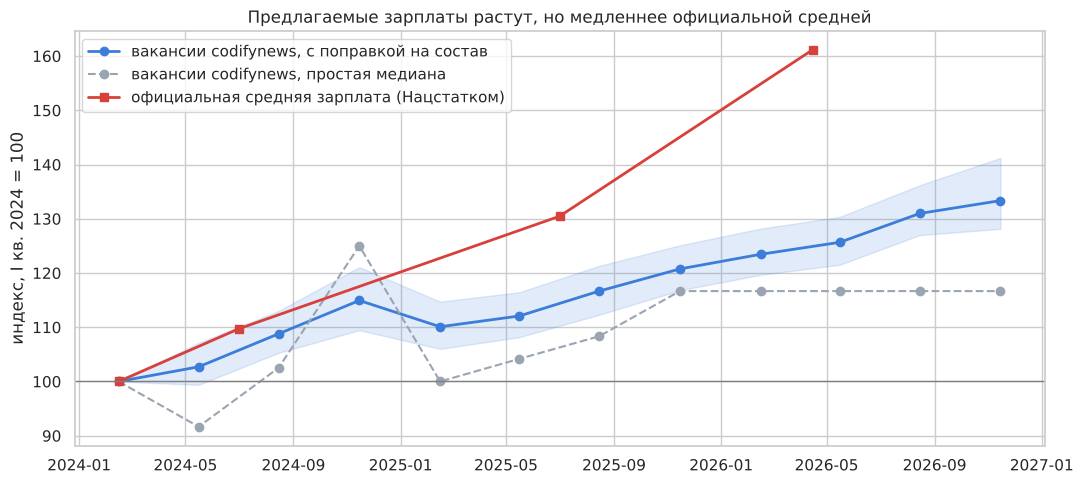

In [5]:
official = pd.DataFrame({
    "period": ["январь–март 2024", "2024 год", "2025 год", "январь–июль 2026"],
    "x": [pd.Timestamp("2024-02-15"), pd.Timestamp("2024-07-01"), pd.Timestamp("2025-07-01"), pd.Timestamp("2026-04-15")],
    "value": [34_046, 37_360, 44_419, 54_864]})
official["index"] = official["value"] / official["value"].iloc[0] * 100

qx = pd.PeriodIndex(by_q.index, freq="Q").to_timestamp(how="start") + pd.Timedelta(days=45)
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(qx, boots.quantile(.025).values, boots.quantile(.975).values, color="#3b7dd8", alpha=.15)
ax.plot(qx, by_q["индекс (I кв. 2024 = 100)"], marker="o", color="#3b7dd8", lw=2, label="вакансии codifynews, с поправкой на состав")
ax.plot(qx, by_q["медиана, индекс"], marker="o", color="#9aa5b1", lw=1.5, ls="--", label="вакансии codifynews, простая медиана")
ax.plot(official["x"], official["index"], marker="s", color="#d8403b", lw=2, label="официальная средняя зарплата (Нацстатком)")
ax.axhline(100, color="grey", lw=1)
ax.set_ylabel("индекс, I кв. 2024 = 100"); ax.legend(loc="upper left")
ax.set_title("Предлагаемые зарплаты растут, но медленнее официальной средней")
plt.tight_layout(); plt.savefig(FIG + "08_index.png", dpi=150); plt.show()

**Как читать:** синяя линия показывает, насколько дороже стала одна и та же вакансия; серая линия это
простая медиана, на которую влияет состав вакансий; красная линия это официальная средняя зарплата
работающих.

**Почему линии могут расходиться:**
- официальная статистика описывает **всех работающих**, включая бюджетный сектор, где зарплаты
  повышались решениями государства; вакансии описывают **предложения частных работодателей** новым сотрудникам;
- в codifynews преобладают офисные, IT и продажные вакансии, где зарплаты и так выше средней;
- снижение доли вакансий в долларах (удалённая IT-работа) тянет простую медиану вниз.

## 4. Какие профессии подорожали сильнее всего (codifynews, 2024 → 2026)

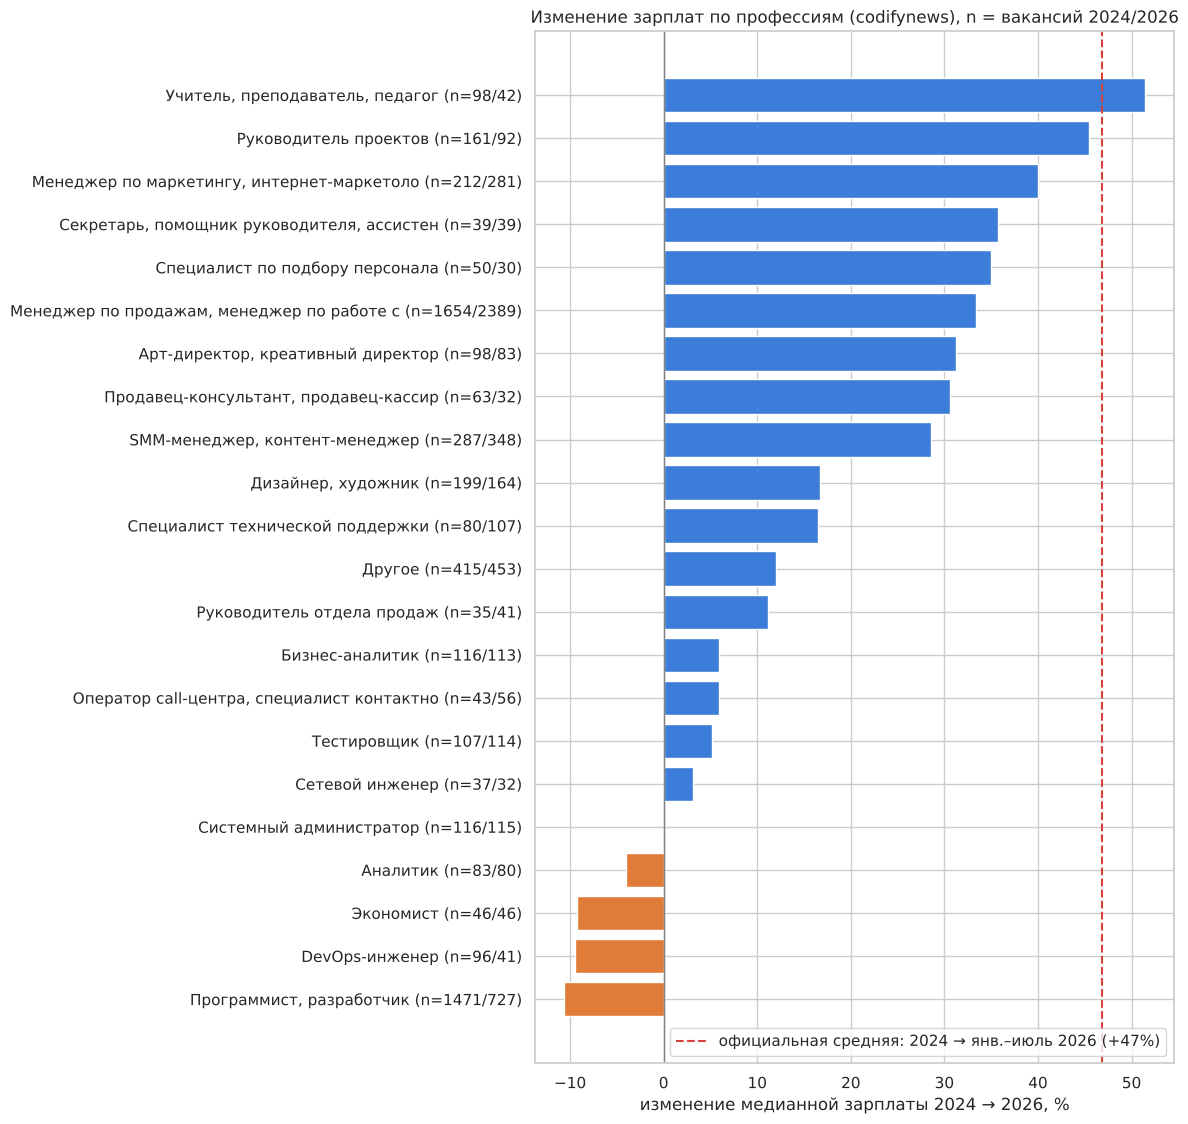

,2024,2026,n_2024,n_2026,"изменение, %"
sub_category,,,,,
"Программист, разработчик","111,860","100,000",1471.000000,727.000000,-11
DevOps-инженер,"132,500","120,000",96.000000,41.000000,-9
Экономист,"99,220","90,000",46.000000,46.000000,-9
Аналитик,"75,000","72,000",83.000000,80.000000,-4
Системный администратор,"50,000","50,000",116.000000,115.000000,+0
Сетевой инженер,"80,000","82,500",37.000000,32.000000,+3
Тестировщик,"76,060","80,000",107.000000,114.000000,+5
"Оператор call-центра, специалист контактного центра","42,500","45,000",43.000000,56.000000,+6
Бизнес-аналитик,"75,530","80,000",116.000000,113.000000,+6


In [6]:
y24 = cod[cod["published"].dt.year == 2024]; y26 = cod[cod["published"].dt.year == 2026]
ch = pd.DataFrame({"2024": y24.groupby("sub_category")["salary_kgs"].median(),
                   "2026": y26.groupby("sub_category")["salary_kgs"].median(),
                   "n_2024": y24.groupby("sub_category").size(), "n_2026": y26.groupby("sub_category").size()}).dropna()
ch = ch[(ch["n_2024"] >= 30) & (ch["n_2026"] >= 30)]
ch["изменение, %"] = (ch["2026"] / ch["2024"] - 1) * 100
ch = ch.sort_values("изменение, %")

fig, ax = plt.subplots(figsize=(12, 0.45 * len(ch) + 1.5))
colors = np.where(ch["изменение, %"] >= 0, "#3b7dd8", "#e07b39")
ax.barh([f"{i[:42]} (n={a:.0f}/{b:.0f})" for i, a, b in zip(ch.index, ch["n_2024"], ch["n_2026"])], ch["изменение, %"], color=colors)
off = (official["value"].iloc[3] / official["value"].iloc[1] - 1) * 100
ax.axvline(off, color="#d8403b", ls="--", lw=1.5, label=f"официальная средняя: 2024 → янв.–июль 2026 (+{off:.0f}%)")
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("изменение медианной зарплаты 2024 → 2026, %"); ax.legend(loc="lower right")
ax.set_title("Изменение зарплат по профессиям (codifynews), n = вакансий 2024/2026")
plt.tight_layout(); plt.savefig(FIG + "08_professions.png", dpi=150); plt.show()
ch.style.format({"2024": "{:,.0f}", "2026": "{:,.0f}", "изменение, %": "{:+.0f}"})

**Почему подешевели программисты?** Проверка по валюте вакансии:

In [7]:
pr = cod[cod["sub_category"] == "Программист, разработчик"].assign(год=lambda x: x["published"].dt.year)
pr.groupby("год").apply(lambda x: pd.Series({
    "вакансий": len(x), "доля в USD/EUR": (x["compensation_currency"] != "KGS").mean(),
    "медиана, все": x["salary_kgs"].median(),
    "медиана, в сомах": x.loc[x["compensation_currency"] == "KGS", "salary_kgs"].median(),
    "медиана, в USD/EUR": x.loc[x["compensation_currency"] != "KGS", "salary_kgs"].median()})
).style.format({"вакансий": "{:.0f}", "доля в USD/EUR": "{:.0%}", "медиана, все": "{:,.0f}",
                "медиана, в сомах": "{:,.0f}", "медиана, в USD/EUR": "{:,.0f}"})

,вакансий,доля в USD/EUR,"медиана, все","медиана, в сомах","медиана, в USD/EUR"
год,,,,,
2024,1471,54%,"111,860","82,500","156,600"
2025,1400,40%,"100,000","85,000","153,040"
2026,727,27%,"100,000","95,000","139,920"


Падение медианы программистов объясняется **составом**, а не тем, что местным разработчикам стали платить
меньше: доля долларовых (обычно зарубежных удалённых) вакансий упала с 54% до 27%, а вакансии в сомах
подорожали с 82 500 до 95 000 сом (+15%). Вакансий программистов с зарплатой: 1 471 в 2024 году и 727 за 10 месяцев 2026.

## 5. Сфера услуг: lalafo 2024 против kgworkzone 2025–2026

Каналы похожи по составу вакансий (общепит, торговля, склады), но это **разные источники**, и проверить
их сопоставимость за один период нельзя: kgworkzone начинается только в ноябре 2025.
Поэтому этот раздел даёт ориентир, а не точную оценку.

In [8]:
la = sal[sal["src"] == "lalafo"]; kz = sal[sal["src"] == "kgworkzone"]
sv = pd.DataFrame({"lalafo 2024": la.groupby("sub_category")["salary_kgs"].median(),
                   "kgworkzone 2025–26": kz.groupby("sub_category")["salary_kgs"].median(),
                   "n_lalafo": la.groupby("sub_category").size(), "n_kg": kz.groupby("sub_category").size()}).dropna()
sv = sv[(sv["n_lalafo"] >= 20) & (sv["n_kg"] >= 20)]
sv["изменение, %"] = (sv["kgworkzone 2025–26"] / sv["lalafo 2024"] - 1) * 100
print(f"Профессий для сравнения: {len(sv)} | медианное изменение: {sv['изменение, %'].median():+.0f}%")
sv.sort_values("изменение, %").style.format({"lalafo 2024": "{:,.0f}", "kgworkzone 2025–26": "{:,.0f}", "изменение, %": "{:+.0f}"})

Профессий для сравнения: 17 | медианное изменение: +35%


,lalafo 2024,kgworkzone 2025–26,n_lalafo,n_kg,"изменение, %"
sub_category,,,,,
Водитель,"77,000","50,000",197.000000,43.000000,-35
Торговый представитель,"45,000","50,000",115.000000,35.000000,+11
"Повар, пекарь, кондитер","39,000","50,700",289.000000,198.000000,+30
Грузчик,"30,000","40,000",51.000000,34.000000,+33
"Продавец-консультант, продавец-кассир","30,000","40,000",220.000000,238.000000,+33
Администратор,"31,900","42,900",42.000000,83.000000,+34
"Официант, бармен, бариста","33,800","45,500",134.000000,109.000000,+35
Агент по недвижимости,"45,000","60,750",25.000000,24.000000,+35
Другие специальности,"32,000","43,350",355.000000,106.000000,+35


## 6. Скрытые зарплаты, валюта и спрос по сферам во времени (codifynews)

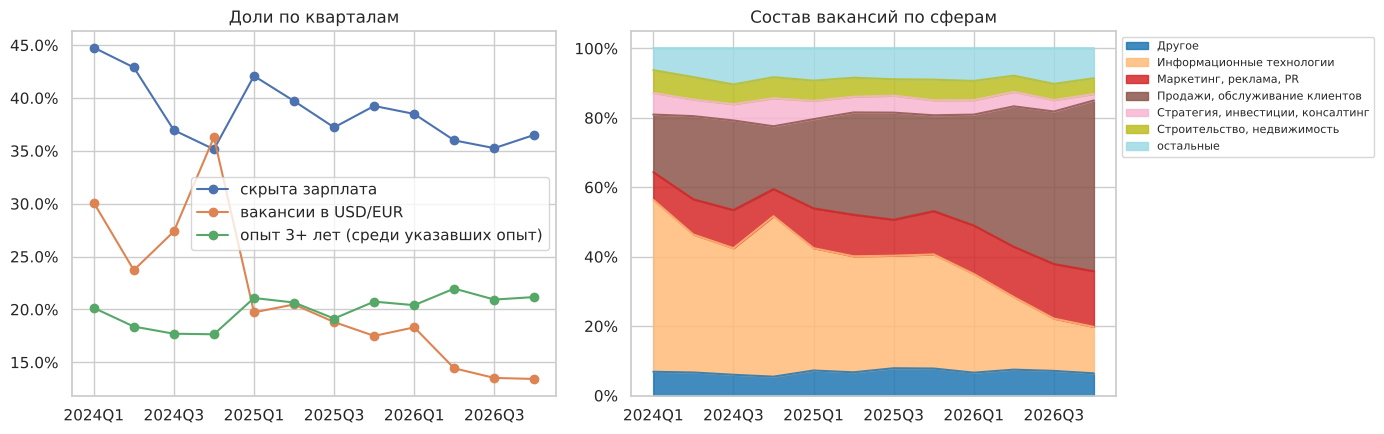

,скрыта зарплата,вакансии в USD/EUR,опыт 3+ лет (среди указавших опыт)
q,,,
2024Q1,45%,30%,20%
2024Q2,43%,24%,18%
2024Q3,37%,27%,18%
2024Q4,35%,36%,18%
2025Q1,42%,20%,21%
2025Q2,40%,20%,21%
2025Q3,37%,19%,19%
2025Q4,39%,17%,21%
2026Q1,38%,18%,20%


In [9]:
codall = df[df["src"] == "codifynews"]
qq = pd.DataFrame({
    "скрыта зарплата": codall.groupby("q")["salary_hidden"].mean(),
    "вакансии в USD/EUR": cod.groupby("q")["compensation_currency"].apply(lambda x: (x != "KGS").mean()),
    "опыт 3+ лет (среди указавших опыт)": codall.groupby("q")["experience_start"].apply(lambda x: (x.dropna() >= 3).mean()),
})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
qq.plot(ax=ax[0], marker="o"); ax[0].yaxis.set_major_formatter(mt.PercentFormatter(1))
ax[0].set_title("Доли по кварталам"); ax[0].set_xlabel(""); ax[0].legend(title="")
top = codall["category"].value_counts().head(6).index
mix = pd.crosstab(codall["q"], codall["category"].where(codall["category"].isin(top), "остальные"), normalize="index")
mix.plot(kind="area", stacked=True, ax=ax[1], alpha=.85, cmap="tab20")
ax[1].yaxis.set_major_formatter(mt.PercentFormatter(1)); ax[1].set_xlabel("")
ax[1].set_title("Состав вакансий по сферам"); ax[1].legend(title="", fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(FIG + "08_shares.png", dpi=150); plt.show()
qq.style.format("{:.0%}")

In [10]:
# Скрытие зарплаты по годам и источникам
pd.crosstab(df["src"], df["published"].dt.year, values=df["salary_hidden"], aggfunc="mean").style.format("{:.0%}", na_rep="")

published,2024,2025,2026
src,,,
codifynews,41%,39%,37%
hh,41%,,
kgworkzone,,61%,39%
lalafo,56%,,


## Выводы

1. **Источники сопоставимы для массовых профессий.** Менеджер по продажам и маркетолог стоят одинаково
   на hh и в codifynews (50 000 сом). В IT codifynews дороже из-за долларовых вакансий, поэтому динамика
   считается внутри одного источника.
2. **Та же вакансия подорожала примерно на 33%** с I квартала 2024 до конца 2026 года
   (индекс 133, 95% интервал 128–141). Рост равномерный: около 0,9% в месяц, без резких скачков.
3. **Простая медиана показывает только +17%** (60 000 → 70 000 сом). Разница в том, что из канала уходят
   дорогие IT-вакансии в долларах: доля USD/EUR упала с 30% до 13%, доля IT в вакансиях с 50% до 13%.
   Без поправки на состав рост зарплат был бы занижен вдвое.
4. **Официальная средняя зарплата росла быстрее:** +61% (34 046 → 54 864 сом, январь–июль 2026).
   Предлагаемые зарплаты в частных вакансиях отстают, вероятная причина: повышения в бюджетном секторе
   и у уже работающих сотрудников, которые не видны в объявлениях.
5. **Сильнее всего подорожали продажи, маркетинг и управление:** менеджер по продажам +33% (52 500 → 70 000 сом),
   маркетолог +40% (50 000 → 70 000), руководитель проектов +45%, учитель +51% (но всего 42 вакансии в 2026).
   **IT почти не растёт:** сисадмин 0%, тестировщик +5%, программист −11% из-за ухода долларовых вакансий
   (в сомах +15%).
6. **Сфера услуг, ориентировочно, +35%** по медиане 17 профессий (lalafo 2024 против kgworkzone 2025–26):
   продавец 30 000 → 40 000, официант 33 800 → 45 500 сом. Это разные источники, поэтому число неточное,
   но направление совпадает с официальной статистикой.
7. **Скрытых зарплат стало немного меньше:** в codifynews 45% в I квартале 2024 и 35–37% в 2026.

**Для модели (репозиторий kg-salary-prediction):** зарплаты 2024 года нужно поднимать примерно на треть
или обучать модель с признаком времени, иначе прогноз для 2026 года будет занижен.